# Mini End-to-End Data Science Project: Customer Churn Prediction
This notebook covers the complete data science workflow:
1. **Data Collection**
2. **Data Cleaning**
3. **Exploratory Data Analysis (EDA)**
4. **Feature Engineering & Preprocessing**
5. **Machine Learning Modeling & Evaluation**
6. **Business Insights & Recommendations**

In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# 1. DATA COLLECTION (Works both Offline and Online)
local_raw_path = '../data/raw/raw_churn_data.csv'
same_folder_path = 'raw_churn_data.csv'
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

if os.path.exists(local_raw_path):
    df = pd.read_csv(local_raw_path)
    print("Loaded dataset offline from ../data/raw/raw_churn_data.csv")
elif os.path.exists(same_folder_path):
    df = pd.read_csv(same_folder_path)
    print("Loaded dataset offline from current folder")
else:
    df = pd.read_csv(url)
    os.makedirs('../data/raw', exist_ok=True)
    df.to_csv(local_raw_path, index=False)
    print("Downloaded dataset from URL and saved locally for future offline use!")

print("1. Raw Dataset Shape:", df.shape)

# 2. DATA CLEANING
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
df.drop('customerID', axis=1, inplace=True)

# Save Final Cleaned Dataset
os.makedirs('../data/processed', exist_ok=True)
df.to_csv('../data/processed/cleaned_churn_data.csv', index=False)
print("2. Cleaned Dataset Saved! Missing values left:", df.isnull().sum().sum())
df.head()

Loaded dataset offline from ../data/raw/raw_churn_data.csv
1. Raw Dataset Shape: (7043, 21)
2. Cleaned Dataset Saved! Missing values left: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


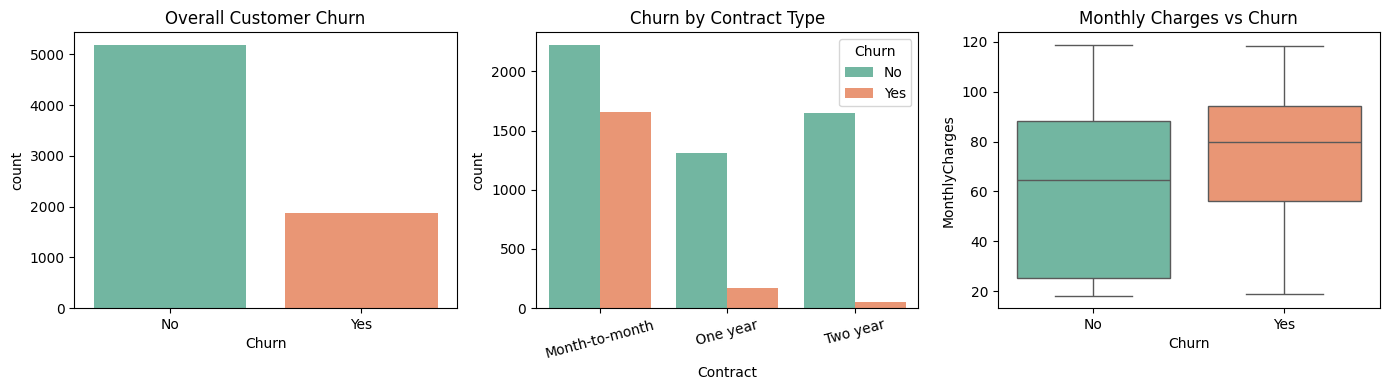

In [13]:
# 3. EXPLORATORY DATA ANALYSIS (EDA)
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Overall Customer Churn')

plt.subplot(1, 3, 2)
sns.countplot(x='Contract', hue='Churn', data=df, palette='Set2')
plt.title('Churn by Contract Type')
plt.xticks(rotation=15)

plt.subplot(1, 3, 3)
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, palette='Set2')
plt.title('Monthly Charges vs Churn')

plt.tight_layout()
plt.show()

In [14]:
# 4. FEATURE ENGINEERING & PREPROCESSING
df_model = df.copy()
le = LabelEncoder()

for col in df_model.select_dtypes(include='object').columns:
    df_model[col] = le.fit_transform(df_model[col])

X = df_model.drop('Churn', axis=1)
y = df_model['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. MODELING & EVALUATION
models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred) * 100
    print(f'Model: {name}')
    print(f'Accuracy: {acc:.2f}%')
    print(classification_report(y_test, y_pred))
    print('-'*50)

Model: Logistic Regression
Accuracy: 81.55%
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.68      0.58      0.62       373

    accuracy                           0.82      1409
   macro avg       0.77      0.74      0.75      1409
weighted avg       0.81      0.82      0.81      1409

--------------------------------------------------
Model: Decision Tree
Accuracy: 79.42%
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      1036
           1       0.61      0.64      0.62       373

    accuracy                           0.79      1409
   macro avg       0.74      0.74      0.74      1409
weighted avg       0.80      0.79      0.80      1409

--------------------------------------------------
Model: Random Forest
Accuracy: 79.63%
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1   